In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/Users/Admin/Documents/proyectosAnalisisDatos/Pandas/Data/sales_data.csv')
display(df.head())

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,176558,Flatscreen TV,3,84.41,2023-01-01,"570 Main St, New York, NY"
1,176559,Wired Headphones,2,1593.83,2023-01-02,"242 Main St, Portland, OR"
2,176560,Macbook Pro Laptop,2,790.31,2023-01-03,"191 Main St, Los Angeles, CA"
3,176561,Flatscreen TV,4,1274.87,2023-01-04,"453 Main St, New York, NY"
4,176562,Google Phone,2,2270.37,2023-01-05,"933 Main St, Portland, OR"


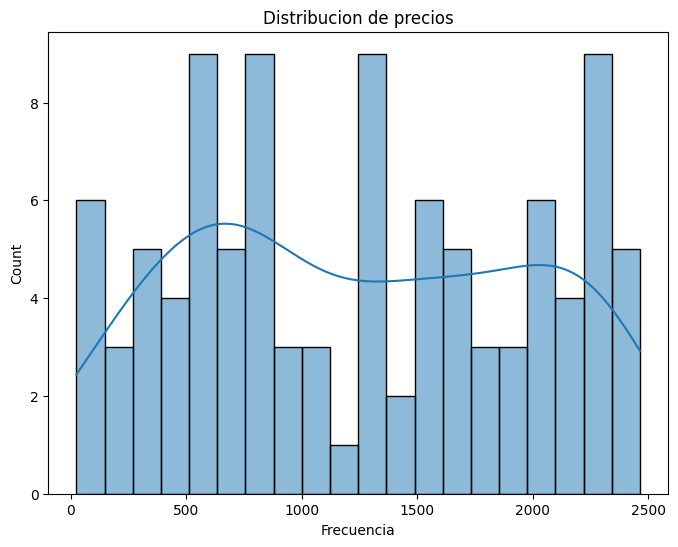

In [7]:
#Distribucion de precios para mirar los que estan fuera de rango 
plt.figure(figsize=(8,6))
sns.histplot(df['Price Each'], bins=20, kde=True)
plt.title('Distribucion de precios')
plt.xlabel('Precio Unitario')
plt.xlabel('Frecuencia')
plt.show()

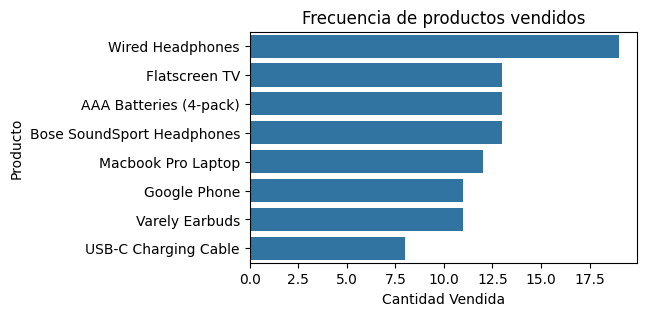

In [9]:
plt.figure(figsize=(5,3))
sns.countplot(data=df, y='Product', order=df['Product'].value_counts().index)
plt.title('Frecuencia de productos vendidos')
plt.xlabel('Cantidad Vendida')
plt.ylabel('Producto')
plt.show()

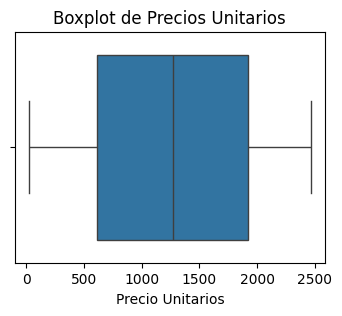

In [10]:
#Graficos de cajas outliers
plt.figure(figsize=(4,3))
sns.boxplot(x=df['Price Each'])
plt.title('Boxplot de Precios Unitarios')
plt.xlabel('Precio Unitarios')
plt.show()

In [ ]:
#Grafico de barras para ventas por ciudad
#Extraer la ciudad 
# Es más rápida que .apply porque es vectorizada.
# separa en hasta 3 columnas: Street, City, StateZip
parts = df['Purchase Address'].astype(str).str.split(',', n=2, expand=True)
df['City_2'] = parts[1].str.strip()   # parts[1] es la columna 'City'

display(df)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,City_2
0,176558,Flatscreen TV,3,84.41,2023-01-01,"570 Main St, New York, NY",New York
1,176559,Wired Headphones,2,1593.83,2023-01-02,"242 Main St, Portland, OR",Portland
2,176560,Macbook Pro Laptop,2,790.31,2023-01-03,"191 Main St, Los Angeles, CA",Los Angeles
3,176561,Flatscreen TV,4,1274.87,2023-01-04,"453 Main St, New York, NY",New York
4,176562,Google Phone,2,2270.37,2023-01-05,"933 Main St, Portland, OR",Portland
...,...,...,...,...,...,...,...
95,176653,AAA Batteries (4-pack),2,877.27,2023-04-06,"193 Main St, Portland, OR",Portland
96,176654,Bose SoundSport Headphones,2,1817.25,2023-04-07,"849 Main St, Portland, OR",Portland
97,176655,Wired Headphones,4,2244.28,2023-04-08,"552 Main St, Los Angeles, CA",Los Angeles
98,176656,AAA Batteries (4-pack),1,2219.27,2023-04-09,"303 Main St, New York, NY",New York


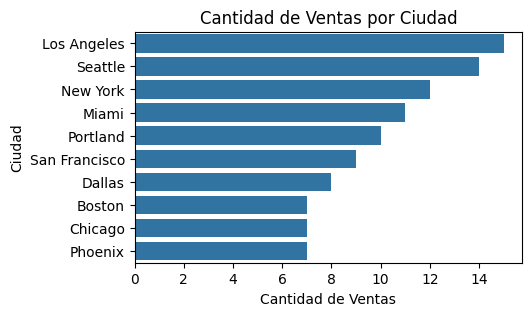

In [13]:
plt.figure(figsize=(5,3))
city_order=df['City_2'].value_counts().index
sns.countplot(data=df,y='City_2',order=city_order)
plt.title('Cantidad de Ventas por Ciudad')
plt.xlabel('Cantidad de Ventas')
plt.ylabel('Ciudad')
plt.show()

In [14]:
#Grafco de lineas para ventas por mes
df['Order Date']= pd.to_datetime(df['Order Date'], errors='coerce')
df['Month']= df['Order Date'].dt.month

display(df)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,City_2,Month
0,176558,Flatscreen TV,3,84.41,2023-01-01,"570 Main St, New York, NY",New York,1
1,176559,Wired Headphones,2,1593.83,2023-01-02,"242 Main St, Portland, OR",Portland,1
2,176560,Macbook Pro Laptop,2,790.31,2023-01-03,"191 Main St, Los Angeles, CA",Los Angeles,1
3,176561,Flatscreen TV,4,1274.87,2023-01-04,"453 Main St, New York, NY",New York,1
4,176562,Google Phone,2,2270.37,2023-01-05,"933 Main St, Portland, OR",Portland,1
...,...,...,...,...,...,...,...,...
95,176653,AAA Batteries (4-pack),2,877.27,2023-04-06,"193 Main St, Portland, OR",Portland,4
96,176654,Bose SoundSport Headphones,2,1817.25,2023-04-07,"849 Main St, Portland, OR",Portland,4
97,176655,Wired Headphones,4,2244.28,2023-04-08,"552 Main St, Los Angeles, CA",Los Angeles,4
98,176656,AAA Batteries (4-pack),1,2219.27,2023-04-09,"303 Main St, New York, NY",New York,4


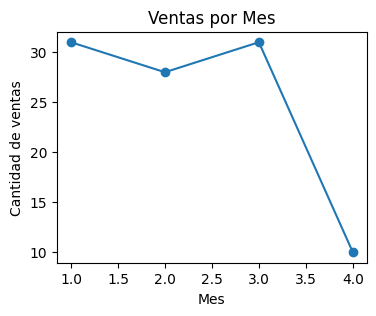

In [18]:
#Graficar las ventas mensuales
ventas_mensuales = df['Month'].value_counts().sort_index()
plt.figure(figsize=(4,3))
plt.plot(ventas_mensuales.index, ventas_mensuales.values, marker='o')
plt.title('Ventas por Mes')
plt.xlabel('Mes')
plt.ylabel('Cantidad de ventas')
plt.show()